# Какие офисы обзвонить в IV квартале 2026 года

Отчёт для руководителя B2B «Зерно для офиса». Данные зафиксированы на 1 октября. Срез для новой кампании — 30 сентября.

[Цель](#1.-Цель) · [Данные](#2.-Данные) · [Предобработка](#3.-Предобработка) · [Анализ](#4.-Анализ-и-модели) · [Рекомендации](#5.-Выводы-и-рекомендации)

In [1]:
import hashlib
import json
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from scipy.stats import fisher_exact
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.model_selection import cross_validate, GroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from src.features import read_tables, active_clients, build_target, build_features, CATEGORY, NUMERIC, FEATURES
from score import call_profit, rank_clients

RANDOM_STATE = 42
DATA = Path('data')
db = DATA / 'office.db'
cuts = ['2025-09-30','2025-12-31','2026-03-31','2026-06-30']
live = '2026-09-30'
print(platform.python_version(), pd.__version__, sklearn.__version__)

3.12.14 3.0.6 1.8.0


## 1. Цель

Из пяти таблиц CRM собрать историю на конец квартала и дать менеджерам не более 150 офисов с положительной ожидаемой прибылью звонка. Для проверки оставляю срез на 30 июня, в сентябре ещё нет ответов на будущий квартал. Ориентиры — ничего не делать, обзвонить всех либо первые 150 по падению выручки.

## 2. Данные

Клиент и договор описывают компанию, заказ — отдельную продажу или возврат, тикет — обращение, счёт — обязательство по оплате. Сначала проверяю состав, полноту, диапазоны дат и ключи. При объединении сохраняю одну строку на офис в конкретном срезе.

In [2]:
raw=read_tables(db)
tables={k:len(v) for k,v in raw.items()}
n_test=int(raw['clients'].is_test.sum())
n_dup_tickets=int(raw['tickets'].ticket_id.duplicated().sum())
orders=raw['orders']
n_returns=int((orders.status=='возврат').sum())
last_order=str(orders.order_date.max().date())
print(tables, 'тестовых офисов',n_test,'повторы тикетов',n_dup_tickets)
print(orders.groupby('status').amount.agg(['size','sum','min','max']))
print('Даты заказов',orders.order_date.min().date(),last_order)
print('Пропуски', {k:v.isna().sum().loc[lambda x:x.gt(0)].to_dict() for k,v in raw.items()})
for name, frame in raw.items():
    assert frame.client_id.isin(raw['clients'].client_id).all()

{'clients': 1503, 'contracts': 1503, 'orders': 67695, 'tickets': 3416, 'invoices': 12951} тестовых офисов 3 повторы тикетов 142
            size           sum      min       max
status                                           
возврат      673 -1.172228e+06 -8601.97   -107.83
доставлен  65615  1.957471e+08     1.00  17088.54
отменён     1407  0.000000e+00     0.00      0.00
Даты заказов 2024-06-04 2026-09-30
Пропуски {'clients': {'industry': 78}, 'contracts': {'end_date': 1029}, 'orders': {}, 'tickets': {}, 'invoices': {'paid_date': 26}}


**Вывод по данным.** Из 1 503 клиентов три тестовые записи. В выручку входят 673 возврата с отрицательной суммой. Для всех срезов исключаю 1 407 отменённых заказов, а из 3 416 строк поддержки удаляю 142 повторные записи. Последний заказ датирован 30 сентября. Пропуск в оплате интерпретирую с учётом срока счёта.

## 3. Предобработка

Даты границ включены справа. Просрочку неоплаченного на дату среза счёта измеряю от срока оплаты до этого среза. Профиль клиента считаю действующим на срезе: история изменения атрибутов в выгрузке отсутствует. Функции расчёта находятся в src/features.py и используются также в score.py.

In [3]:
def snapshot(cut):
    frame=build_features(raw,cut)
    target=build_target(raw,cut)
    return frame.join(target).assign(cutoff=cut).reset_index()

snapshots=[snapshot(cut) for cut in cuts]
rates={cut:(len(v),round(v.churn.mean(),3)) for cut,v in zip(cuts,snapshots)}
train=pd.concat(snapshots[:3],ignore_index=True)
test=snapshots[-1].copy()
def order_features(cutoff):
    return build_features(raw,cutoff)[['orders_90','revenue_90','days_since_order']]
feat=order_features(cuts[-1])
means=feat.mean().round(3).to_dict()
print(rates, 'Уникальных офисов в обучении',train.client_id.nunique())
print(test[NUMERIC].mean().round(3))
out_of_range={c:int((~build_features(raw,c).revenue_trend.between(-1,1)).sum()) for c in cuts+[live]}
print('Тренд вне интервала [−1;1]',out_of_range)
known=test.client_id.isin(train.client_id)
print('Знакомые и новые офисы в тесте',known.value_counts().to_dict())
assert not train.duplicated(['client_id','cutoff']).any()
assert train[FEATURES].isna().sum().sum()==0

{'2025-09-30': (628, np.float64(0.065)), '2025-12-31': (763, np.float64(0.073)), '2026-03-31': (888, np.float64(0.13)), '2026-06-30': (965, np.float64(0.136))} Уникальных офисов в обучении 985
employees              51.552
has_manager             0.134
own_machine             0.348
tenure_days           292.877
orders_90              13.230
revenue_90          39915.848
revenue_trend           0.250
days_since_order        9.150
late_share_90           0.080
tickets_90              0.623
tickets_bill_90         0.065
pay_late_last3          0.944
overdue_now             0.028
dtype: float64


Тренд вне интервала [−1;1] {'2025-09-30': 1, '2025-12-31': 0, '2026-03-31': 2, '2026-06-30': 2, '2026-09-30': 1}
Знакомые и новые офисы в тесте {True: 773, False: 192}


In [4]:
cut=pd.Timestamp(cuts[-1])
hist=orders[orders.status!='отменён']
n_future=int((hist.order_date>cut).sum())
bad_last=hist.groupby('client_id').order_date.max()
days=(cut-test.client_id.map(bad_last)).dt.days.fillna(0)
auc_honest=round(roc_auc_score(test.churn,test.days_since_order),3)
auc_leaky=round(roc_auc_score(test.churn,days),3)
print('AUC давности заказа',auc_honest,'с будущими заказами',auc_leaky,'строк из будущего',n_future)
trim=raw.copy()
trim['orders']=raw['orders'].loc[raw['orders'].order_date<=cut]
trim['tickets']=raw['tickets'].loc[raw['tickets'].created_at<=cut]
trim['invoices']=raw['invoices'].loc[raw['invoices'].due_date<=cut].copy()
trim['invoices']['paid_date']=trim['invoices'].paid_date.where(trim['invoices'].paid_date<=cut)
pd.testing.assert_frame_equal(build_features(trim,cut),build_features(raw,cut))

AUC давности заказа 0.706 с будущими заказами 0.981 строк из будущего 13486


**Вывод по предобработке.** В трёх обучающих срезах 2 279 наблюдений на 985 организаций. После физического удаления будущих заказов, обращений, счетов и оплат все расчётные признаки остались теми же. AUC единственного признака вырос с 0,706 до 0,981 после включения будущих заказов. В пяти срезах число значений revenue_trend вне [−1;1] составило 1, 0, 2, 2 и 1. Отрицательная квартальная выручка из-за возвратов нарушает границу, указанную в брифе. Сохраняю исходную формулу и отображаю эти случаи отдельно: обрезка изменила бы порядок клиентов у правила падения выручки.

## 4. Анализ и модели

В обучении один офис встречается несколько раз. Фиксирую пять фолдов по client_id и критерий выбора — средний ROC-AUC. Для сравнения считаю также average precision, где ориентир зависит от доли уходящих. Июньский тест использую для итогового отчёта. Состав и настройки моделей зафиксированы заранее.

In [5]:
def prepare(cat=CATEGORY,scale=True):
    return ColumnTransformer([('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat),
                              ('num', StandardScaler() if scale else 'passthrough', NUMERIC)])

models={'dummy':make_pipeline(prepare(),DummyClassifier(strategy='prior')),
        'logreg':make_pipeline(prepare(),LogisticRegression(max_iter=2000)),
        'boosting':make_pipeline(prepare(scale=False),HistGradientBoostingClassifier(max_depth=3,learning_rate=.05,max_iter=200,random_state=RANDOM_STATE)),
        'knn':make_pipeline(prepare(),KNeighborsClassifier(n_neighbors=25))}
X,y=train[FEATURES],train.churn
folds=list(GroupKFold(5).split(X,y,train.client_id))
assert all(set(train.client_id.iloc[a]).isdisjoint(train.client_id.iloc[b]) for a,b in folds)
metrics={'roc':'roc_auc','ap':'average_precision'}
rows=[]
for name,m in models.items():
    scores=cross_validate(m,X,y,cv=folds,scoring=metrics)
    rows.append([name,*[fn(scores['test_'+key]) for key in metrics for fn in (np.mean,np.std)]])
cv=pd.DataFrame(rows,columns=['model','roc','roc_sd','ap','ap_sd']).set_index('model')
cv_auc=cv.drop(index='dummy').roc.round(3).to_dict()
best=cv.roc.idxmax()
print(cv.round(3))
ablation=make_pipeline(prepare([c for c in CATEGORY if c!='industry']),LogisticRegression(max_iter=2000))
no_ind=cross_validate(ablation,X,y,cv=folds,scoring='roc_auc')['test_score']
print('ROC-AUC без отрасли',no_ind.mean())

            roc  roc_sd     ap  ap_sd
model                                
dummy     0.500   0.000  0.093  0.007
logreg    0.792   0.038  0.392  0.031
boosting  0.764   0.044  0.404  0.062
knn       0.724   0.040  0.335  0.048
ROC-AUC без отрасли 0.7943197259322803


In [6]:
model=models[best].fit(X,y)
test['p']=model.predict_proba(test[FEATURES])[:,1]
test_auc=round(roc_auc_score(test.churn,test.p),3)
test_ap=average_precision_score(test.churn,test.p)
cal=test.groupby(pd.qcut(test.p,5,duplicates='drop'),observed=True).agg(n=('churn','size'),pred=('p','mean'),observed=('churn','mean'))
print('ROC-AUC',test_auc,'average precision',test_ap,'Brier',brier_score_loss(test.churn,test.p))
print(cal.round(3))
cohorts=test.assign(знакомый=known).groupby('знакомый').agg(n=('churn','size'),pred=('p','mean'),actual=('churn','mean'))
print(cohorts.round(3))

ROC-AUC 0.836 average precision 0.5303784468644185 Brier 0.09088380414133268
                       n   pred  observed
p                                        
(-0.000736, 0.0127]  193  0.006     0.021
(0.0127, 0.0287]     193  0.020     0.047
(0.0287, 0.0558]     193  0.041     0.041
(0.0558, 0.113]      193  0.077     0.155
(0.113, 0.9]         193  0.300     0.415
            n   pred  actual
знакомый                    
False     192  0.116   0.214
True      773  0.082   0.116


**Вывод по моделям.** Выбираю логистическую регрессию по групповым фолдам. На позднем тесте рейтинг стал лучше. Срез сильнее разделён географически, а город есть в модели. GroupKFold проверяет перенос на незнакомый офис. В июньском тесте 773 из 965 офисов уже встречались в обучении, остальные 192 появились позже. Такой состав соответствует квартальной работе CRM. В верхней пятой части теста модель оценила риск в среднем в 30,0 %, ушло 41,5 %. Заниженный риск уменьшает оценку прибыли и может оставить прибыльные звонки вне списка. В новом периоде проверю калибровку, когда станут известны метки; параметры классификатора на июньских ответах не выбираю.

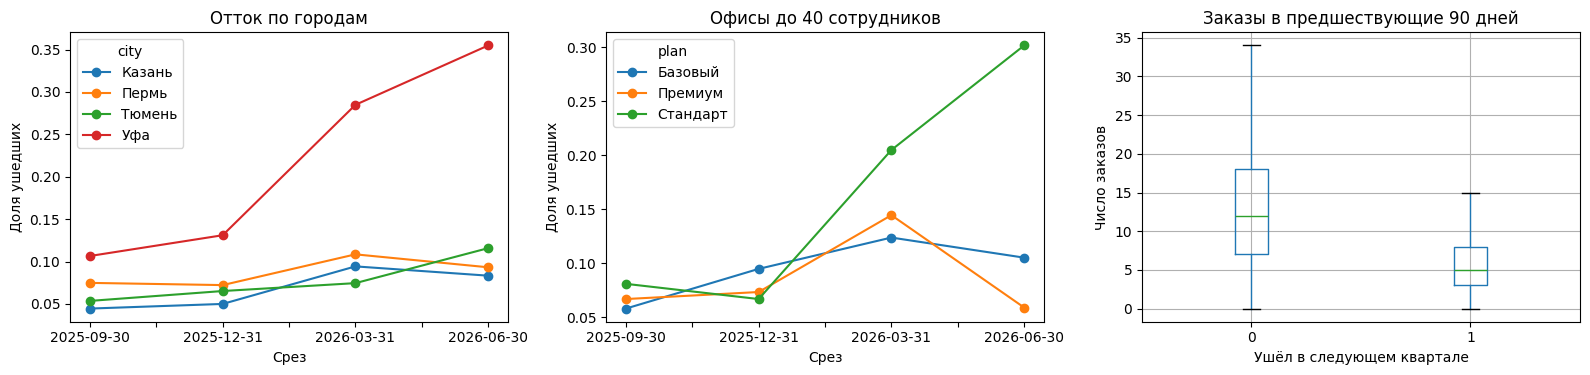

city        Казань  Пермь  Тюмень    Уфа
cutoff                                  
2025-09-30   0.045  0.075   0.054  0.107
2025-12-31   0.050  0.072   0.065  0.131
2026-03-31   0.094  0.108   0.075  0.285
2026-06-30   0.083  0.093   0.116  0.355
plan        Базовый  Премиум  Стандарт
cutoff                                
2025-09-30    0.058    0.067     0.081
2025-12-31    0.095    0.073     0.067
2026-03-31    0.124    0.144     0.205
2026-06-30    0.105    0.059     0.301
медианы числа заказов churn
0    12.0
1     5.0
Name: orders_90, dtype: float64
churn    0   1
city          
False  734  76
True   100  55
Двусторонний точный тест Фишера 7.217206647375147e-15
num__orders_90              -1.272
cat__industry_IT            -0.450
cat__industry_финансы       -0.363
num__own_machine            -0.328
num__has_manager            -0.314
cat__city_Тюмень            -0.303
num__employees               0.237
cat__industry_госсектор      0.241
cat__industry_услуги         0.256
cat__indust

In [7]:
eda=pd.concat(snapshots,ignore_index=True)
city=eda.pivot_table(index='cutoff',columns='city',values='churn',aggfunc='mean')
small=eda[eda.employees<40].pivot_table(index='cutoff',columns='plan',values='churn',aggfunc='mean')
fig,axes=plt.subplots(1,3,figsize=(16,4))
city.plot(ax=axes[0],marker='o',title='Отток по городам',xlabel='Срез',ylabel='Доля ушедших')
small.plot(ax=axes[1],marker='o',title='Офисы до 40 сотрудников',xlabel='Срез',ylabel='Доля ушедших')
test.boxplot(column='orders_90',by='churn',ax=axes[2],showfliers=False)
axes[2].set(title='Заказы в предшествующие 90 дней',xlabel='Ушёл в следующем квартале',ylabel='Число заказов')
fig.suptitle('')
fig.tight_layout()
plt.show()
print(city.round(3),small.round(3),sep='\n')
print('медианы числа заказов',test.groupby('churn').orders_90.median())
ct=pd.crosstab(test.city=='Уфа',test.churn)
print(ct)
print('Двусторонний точный тест Фишера',fisher_exact(ct).pvalue)
w=pd.Series(model[-1].coef_[0],index=model[0].get_feature_names_out()).sort_values()
print(pd.concat([w.head(6),w.tail(6)]).round(3))

**Вывод по анализу.** В июньском срезе ушли 35,5 % офисов Уфы и около 9,4 % в других городах вместе. У малых офисов «Стандарта» ушли 30,1 %, у «Базового» — 10,5 %. Эти различия, жалобы и снижение заказов дают предмет для проверки после смены службы доставки и тарифа. Размер офиса, тариф и закрепление менеджера взаимосвязаны. Сравнение долей само по себе не измеряет причинный эффект.

In [8]:
economy={'save':.5,'margin':.35,'months':12,'call_cost':1500,'discount':.10,'discount_months':2,'limit':150}
test_idx=test.set_index('client_id')
def policy_row(policy,ids,save):
    econ=dict(economy,save=save)
    v=test_idx.loc[ids]
    value=call_profit(v.revenue_90/3,v.churn,econ)
    return {'стратегия':policy,'удержание':save,'звонки':len(v),'ушли':int(v.churn.sum()),'рубли':round(value.sum())}

results=[]
for save in [.3,.5,.7]:
    ids=rank_clients(test_idx,test.p.to_numpy(),dict(economy,save=save)).client_id
    results.append(policy_row('модель',ids,save))
for name,ids in [('правило',test_idx.nsmallest(150,'revenue_trend').index),('все',test_idx.index),('без звонков',[])]:
    results.append(policy_row(name,ids,.5))
money=pd.DataFrame(results)
_,_,n_calls,caught,profit_model=results[1].values()
profit_rule,profit_all=results[3]['рубли'],results[4]['рубли']
print(money.to_string(index=False))
base_ids=rank_clients(test_idx,test.p.to_numpy(),economy).client_id
fixed_money=pd.DataFrame([policy_row('фиксированные 66',base_ids,s) for s in [.3,.5,.7]])
print(fixed_money.to_string(index=False))

  стратегия  удержание  звонки  ушли    рубли
     модель        0.3      34    20    70038
     модель        0.5      66    34   260021
     модель        0.7      97    45   501392
    правило        0.5     150    30  -227324
        все        0.5     965   131 -2446569
без звонков        0.5       0     0        0
       стратегия  удержание  звонки  ушли  рубли
фиксированные 66        0.3      66    34  58010
фиксированные 66        0.5      66    34 260021
фиксированные 66        0.7      66    34 462033


**Вывод по деньгам.** Список отсекает звонки, у которых перспективная годовая маржа не покрывает скидку и время менеджера. При проверке подставляю фактические расторжения; доля спасённых и продолжительность удержания по-прежнему сценарные параметры. Лимит 150 не обязывает делать 150 звонков.

In [9]:
full=pd.concat([train,test],ignore_index=True)
final=models[best].fit(full[FEATURES],full.churn)
fresh=build_features(raw,live)
prob=final.predict_proba(fresh)[:,1]
call_list=rank_clients(fresh,prob,economy)
artifact=Path('models/office_churn/1.0')
artifact.mkdir(parents=True,exist_ok=True)
joblib.dump(final,artifact/'model.joblib')
sal=call_list.exp_profit.sum()
passport={'model':best,'version':'1.0','cutoff':live,'training_cutoffs':cuts,'features':FEATURES,
          'feature_types':fresh.dtypes.astype(str).to_dict(),'train_rows':len(full),'n_calls':len(call_list),
          'expected_profit':round(sal),'data_md5':hashlib.md5(db.read_bytes()).hexdigest(),
          'python':platform.python_version(),'sklearn':sklearn.__version__,'cv':cv.loc[best].to_dict(),
          'test_roc_auc':float(test_auc),'test_average_precision':float(test_ap),
          'economy':economy,'decision':'exp_profit > 0; sort exp_profit descending, then client_id; limit 150'}
(artifact/'passport.json').write_text(json.dumps(passport,ensure_ascii=False,indent=2))
gold=fresh.iloc[:20].copy()
gold['expected']=final.predict_proba(gold[FEATURES])[:,1]
gold.to_csv(artifact/'golden.csv')
loaded=joblib.load(artifact/'model.joblib')
g=pd.read_csv(artifact/'golden.csv')
print('Максимальное расхождение',np.max(np.abs(loaded.predict_proba(g[FEATURES])[:,1]-g.expected)))
assert np.allclose(loaded.predict_proba(g[FEATURES])[:,1],g.expected,atol=1e-9,rtol=0)
Path('reports').mkdir(exist_ok=True)
call_list.round({'exp_profit':0,'p_churn':3}).to_csv(f'reports/call_list_{live}.csv',index=False)
print('Офисов, звонков, ожидаемых рублей',len(fresh),len(call_list),round(sal))
print(call_list.city.value_counts().to_string())

Максимальное расхождение 9.71445146547012e-17
Офисов, звонков, ожидаемых рублей 1027 65 443403
city
Уфа       31
Пермь     15
Казань    12
Тюмень     7


**Вывод по выпуску.** На 30 сентября список содержит 65 записей и 443 403 ₽ ожидаемого эффекта, в том числе 31 офис в Уфе. Вероятности 20 контрольных строк совпали после загрузки файла модели с точностью лучше 10⁻⁹. Скрипт score.py применяет тот же код признаков к заданной дате.

## 5. Выводы и рекомендации

1. На 30 сентября передаю CRM 65 офисов с положительной ожидаемой ценностью. Начать со строк с наибольшим exp_profit. Удержание половины потенциальных уходов и год маржи — предположения Б2Б.
2. На июньском тесте 66 звонков охватывают 34 будущих ухода. При указанных условиях ожидаемая по фактическим меткам прибыль около 260 тыс. ₽ против убытка около 227 тыс. ₽ для правила падения выручки и 2,45 млн ₽ при обзвоне всех.
3. При переотборе стратегии под 30 % успешного удержания объём снижается до 34 звонков и около 70 тыс. ₽, при 70 % вырастает до 97 и около 501 тыс. ₽. Фактическую отдачу измерить случайным разделением подходящих офисов на звонок и контроль.
4. Проверить соблюдение сроков доставки в Уфе и отдельно условия «Стандарта» для небольших офисов. Менеджеры и наличие кофемашины связаны с меньшим прогнозируемым риском, при этом сами назначаются разным по размеру и истории офисам.
5. Аналитик обновляет базу, запускает score.py с новой датой и проверяет размер списка и доли по городам. Когда квартал закончится, сверяет реальные частоты уходов с предсказанными и сравнивает тестовую и контрольную группы.